In [1]:
import pandas as pd

X_train = pd.read_csv("train/X_train.txt", sep=r"\s+", header=None)
X_test = pd.read_csv("test/X_test.txt", sep=r"\s+", header=None)

y_train = pd.read_csv("train/y_train.txt", sep=r"\s+", header=None)
y_test = pd.read_csv("test/y_test.txt", sep=r"\s+", header=None)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (7352, 561)
X_test : (2947, 561)
y_train: (7352, 1)
y_test : (2947, 1)


In [2]:
features = pd.read_csv(
    "features.txt",
    sep=r"\s+",
    header=None,
    names=["id", "feature"]
)

print(features.head())
print("Number of features:", len(features))

   id            feature
0   1  tBodyAcc-mean()-X
1   2  tBodyAcc-mean()-Y
2   3  tBodyAcc-mean()-Z
3   4   tBodyAcc-std()-X
4   5   tBodyAcc-std()-Y
Number of features: 561


In [3]:
X_train.columns = features["feature"]
X_test.columns = features["feature"]

print(X_train.head())

feature  tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
0                 0.288585          -0.020294          -0.132905   
1                 0.278419          -0.016411          -0.123520   
2                 0.279653          -0.019467          -0.113462   
3                 0.279174          -0.026201          -0.123283   
4                 0.276629          -0.016570          -0.115362   

feature  tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  \
0               -0.995279         -0.983111         -0.913526   
1               -0.998245         -0.975300         -0.960322   
2               -0.995380         -0.967187         -0.978944   
3               -0.996091         -0.983403         -0.990675   
4               -0.998139         -0.980817         -0.990482   

feature  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  tBodyAcc-mad()-Z  \
0               -0.995112         -0.983185         -0.923527   
1               -0.998807         -0.974914         -0.957686   
2    

In [4]:
# feature names attached 

In [5]:
activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["id", "activity"]
)

print(activity_labels)

   id            activity
0   1             WALKING
1   2    WALKING_UPSTAIRS
2   3  WALKING_DOWNSTAIRS
3   4             SITTING
4   5            STANDING
5   6              LAYING


In [6]:
label_map = dict(zip(activity_labels["id"], activity_labels["activity"]))

y_train = y_train[0].map(label_map)
y_test = y_test[0].map(label_map)

print(y_train.head())

0    STANDING
1    STANDING
2    STANDING
3    STANDING
4    STANDING
Name: 0, dtype: object


# architecture of the model ->
"""
X_train + y_train
       ↓
   Train model
       ↓
   Trained model
       ↓
     X_test
       ↓
 Predictions
       ↓
Compare with y_test
       ↓
 ┌───────────────┐
 │ Accuracy      │
 │ F1-score      │
 │ Inference time│
 └───────────────┘
 """

In [7]:
# Remove the feature names and use simple unique column numbers
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()

print(X_train.shape)
print(X_test.shape)

(7352, 561)
(2947, 561)


# Regression

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import time

# Create model
model_lr = LogisticRegression(max_iter=2000)

# Train
start_train = time.perf_counter()
model_lr.fit(X_train, y_train)
train_time = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_lr = model_lr.predict(X_test)
inference_time = time.perf_counter() - start_inference

# Metrics
accuracy_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="macro")

print("Logistic Regression")
print("-------------------")
print(f"Accuracy       : {accuracy_lr:.4f}")
print(f"Macro F1-score : {f1_lr:.4f}")
print(f"Train time     : {train_time:.4f} seconds")
print(f"Inference time : {inference_time:.6f} seconds")

Logistic Regression
-------------------
Accuracy       : 0.9606
Macro F1-score : 0.9606
Train time     : 0.8440 seconds
Inference time : 0.001608 seconds


# Decision tree

In [9]:
from sklearn.tree import DecisionTreeClassifier

# Create model
model_dt = DecisionTreeClassifier(random_state=42)

# Train
start_train = time.perf_counter()
model_dt.fit(X_train, y_train)
train_time_dt = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_dt = model_dt.predict(X_test)
inference_time_dt = time.perf_counter() - start_inference

# Metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt, average="macro")

print("Decision Tree")
print("-------------")
print(f"Accuracy       : {accuracy_dt:.4f}")
print(f"Macro F1-score : {f1_dt:.4f}")
print(f"Train time     : {train_time_dt:.4f} seconds")
print(f"Inference time : {inference_time_dt:.6f} seconds")

Decision Tree
-------------
Accuracy       : 0.8626
Macro F1-score : 0.8598
Train time     : 2.1954 seconds
Inference time : 0.001709 seconds


# Random forest

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Create model
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
start_train = time.perf_counter()
model_rf.fit(X_train, y_train)
train_time_rf = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_rf = model_rf.predict(X_test)
inference_time_rf = time.perf_counter() - start_inference

# Metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="macro")

print("Random Forest")
print("-------------")
print(f"Accuracy       : {accuracy_rf:.4f}")
print(f"Macro F1-score : {f1_rf:.4f}")
print(f"Train time     : {train_time_rf:.4f} seconds")
print(f"Inference time : {inference_time_rf:.6f} seconds")

Random Forest
-------------
Accuracy       : 0.9250
Macro F1-score : 0.9234
Train time     : 0.9417 seconds
Inference time : 0.012935 seconds


# SVM

In [11]:
from sklearn.svm import SVC

# Create model
model_svm = SVC(kernel="rbf")

# Train
start_train = time.perf_counter()
model_svm.fit(X_train, y_train)
train_time_svm = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_svm = model_svm.predict(X_test)
inference_time_svm = time.perf_counter() - start_inference

# Metrics
accuracy_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average="macro")

print("SVM (RBF)")
print("---------")
print(f"Accuracy       : {accuracy_svm:.4f}")
print(f"Macro F1-score : {f1_svm:.4f}")
print(f"Train time     : {train_time_svm:.4f} seconds")
print(f"Inference time : {inference_time_svm:.6f} seconds")

SVM (RBF)
---------
Accuracy       : 0.9505
Macro F1-score : 0.9499
Train time     : 0.6362 seconds
Inference time : 1.177624 seconds


# XG BOOST

In [12]:
from xgboost import XGBClassifier

# Convert labels to integers 0-5
label_to_int = {
    "WALKING": 0,
    "WALKING_UPSTAIRS": 1,
    "WALKING_DOWNSTAIRS": 2,
    "SITTING": 3,
    "STANDING": 4,
    "LAYING": 5
}

y_train_xgb = y_train.map(label_to_int)
y_test_xgb = y_test.map(label_to_int)

model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

# Train
start_train = time.perf_counter()
model_xgb.fit(X_train, y_train_xgb)
train_time_xgb = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_xgb = model_xgb.predict(X_test)
inference_time_xgb = time.perf_counter() - start_inference

# Metrics
accuracy_xgb = accuracy_score(y_test_xgb, y_pred_xgb)
f1_xgb = f1_score(y_test_xgb, y_pred_xgb, average="macro")

print("XGBoost")
print("-------")
print(f"Accuracy       : {accuracy_xgb:.4f}")
print(f"Macro F1-score : {f1_xgb:.4f}")
print(f"Train time     : {train_time_xgb:.4f} seconds")
print(f"Inference time : {inference_time_xgb:.6f} seconds")

XGBoost
-------
Accuracy       : 0.9318
Macro F1-score : 0.9310
Train time     : 4.9811 seconds
Inference time : 0.005409 seconds


# KNN

In [13]:
from sklearn.neighbors import KNeighborsClassifier

# Create model
model_knn = KNeighborsClassifier(n_neighbors=5)

# Train
start_train = time.perf_counter()
model_knn.fit(X_train, y_train)
train_time_knn = time.perf_counter() - start_train

# Inference
start_inference = time.perf_counter()
y_pred_knn = model_knn.predict(X_test)
inference_time_knn = time.perf_counter() - start_inference

# Metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn, average="macro")

print("KNN")
print("---")
print(f"Accuracy       : {accuracy_knn:.4f}")
print(f"Macro F1-score : {f1_knn:.4f}")
print(f"Train time     : {train_time_knn:.4f} seconds")
print(f"Inference time : {inference_time_knn:.6f} seconds")

KNN
---
Accuracy       : 0.9002
Macro F1-score : 0.8970
Train time     : 0.0096 seconds
Inference time : 0.131950 seconds


# confusion matrix regression

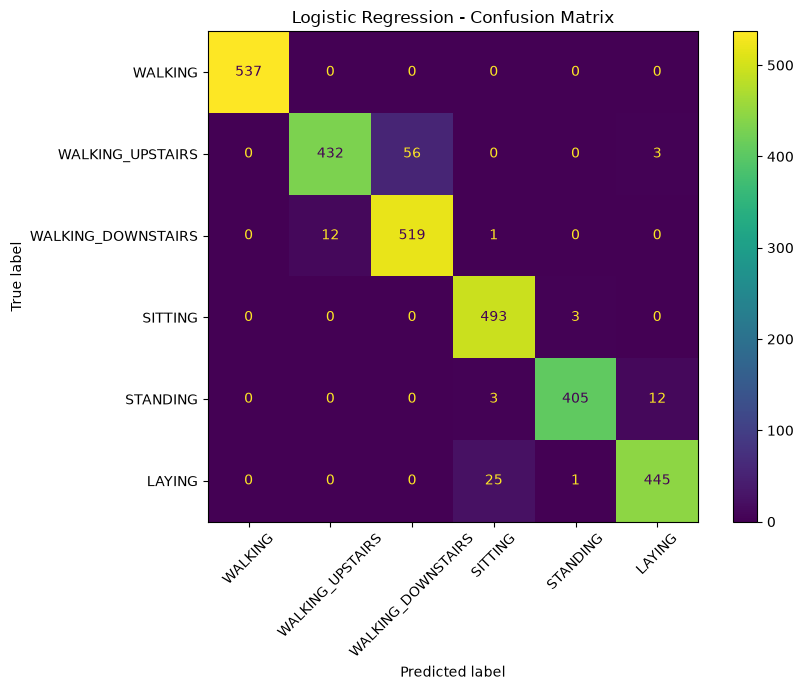

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=activity_labels["activity"]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, xticks_rotation=45)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_lr,
    digits=4
))

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.9730    0.8798    0.9241       491
          STANDING     0.9026    0.9756    0.9377       532
           WALKING     0.9444    0.9940    0.9686       496
WALKING_DOWNSTAIRS     0.9902    0.9643    0.9771       420
  WALKING_UPSTAIRS     0.9674    0.9448    0.9560       471

          accuracy                         0.9606      2947
         macro avg     0.9629    0.9597    0.9606      2947
      weighted avg     0.9620    0.9606    0.9605      2947



In [16]:
results = {
    "Logistic Regression": {
        "accuracy": accuracy_lr,
        "f1": f1_lr,
        "inference_time": inference_time
    },
    "Decision Tree": {
        "accuracy": accuracy_dt,
        "f1": f1_dt,
        "inference_time": inference_time_dt
    },
    "Random Forest": {
        "accuracy": accuracy_rf,
        "f1": f1_rf,
        "inference_time": inference_time_rf
    },
    "SVM": {
        "accuracy": accuracy_svm,
        "f1": f1_svm,
        "inference_time": inference_time_svm
    },
    "XGBoost": {
        "accuracy": accuracy_xgb,
        "f1": f1_xgb,
        "inference_time": inference_time_xgb
    },
    "KNN": {
        "accuracy": accuracy_knn,
        "f1": f1_knn,
        "inference_time": inference_time_knn
    }
}

results_df = pd.DataFrame(results).T

print(results_df)

                     accuracy        f1  inference_time
Logistic Regression  0.960638  0.960557        0.001608
Decision Tree        0.862572  0.859807        0.001709
Random Forest        0.925008  0.923431        0.012935
SVM                  0.950458  0.949907        1.177624
XGBoost              0.931795  0.931018        0.005409
KNN                  0.900238  0.897020        0.131950


In [17]:
results_plot = results_df.copy()

results_plot["accuracy"] *= 100
results_plot["f1"] *= 100

print(results_plot)

                      accuracy         f1  inference_time
Logistic Regression  96.063794  96.055692        0.001608
Decision Tree        86.257211  85.980702        0.001709
Random Forest        92.500848  92.343103        0.012935
SVM                  95.045809  94.990672        1.177624
XGBoost              93.179505  93.101829        0.005409
KNN                  90.023753  89.702030        0.131950


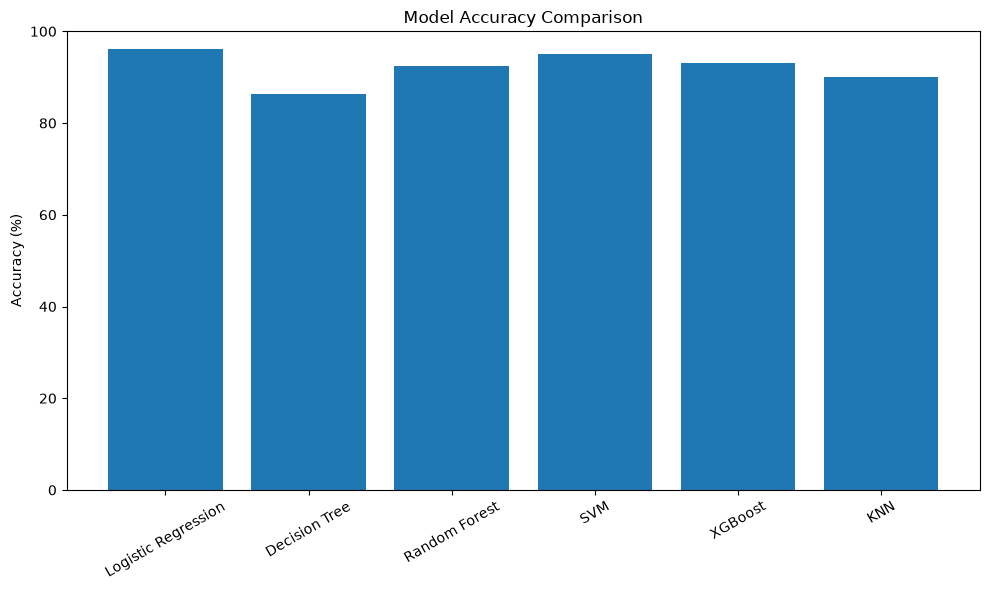

In [18]:
plt.figure(figsize=(10, 6))

plt.bar(results_plot.index, results_plot["accuracy"])

plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

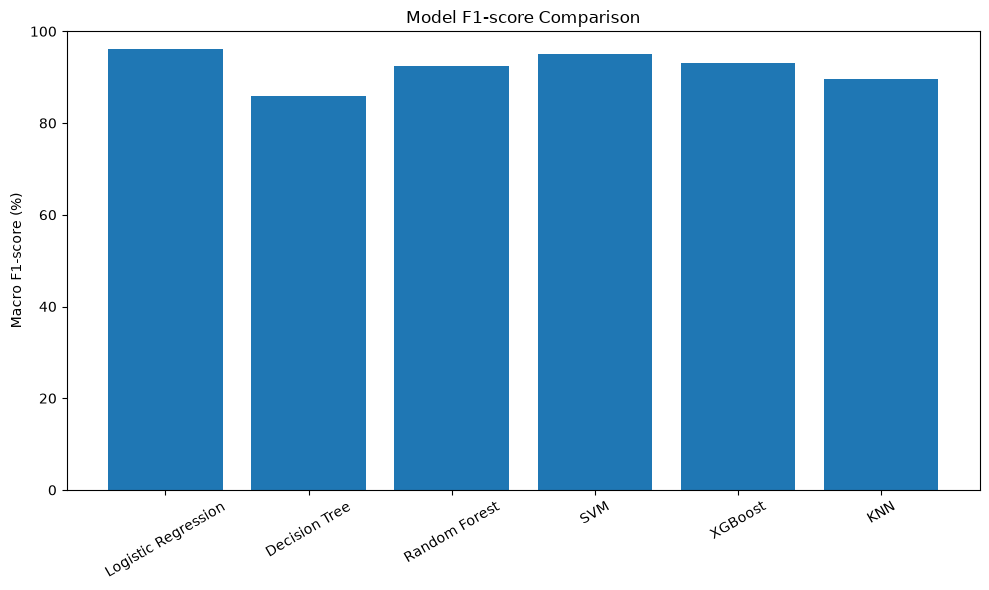

In [19]:
plt.figure(figsize=(10, 6))

plt.bar(results_plot.index, results_plot["f1"])

plt.ylabel("Macro F1-score (%)")
plt.title("Model F1-score Comparison")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

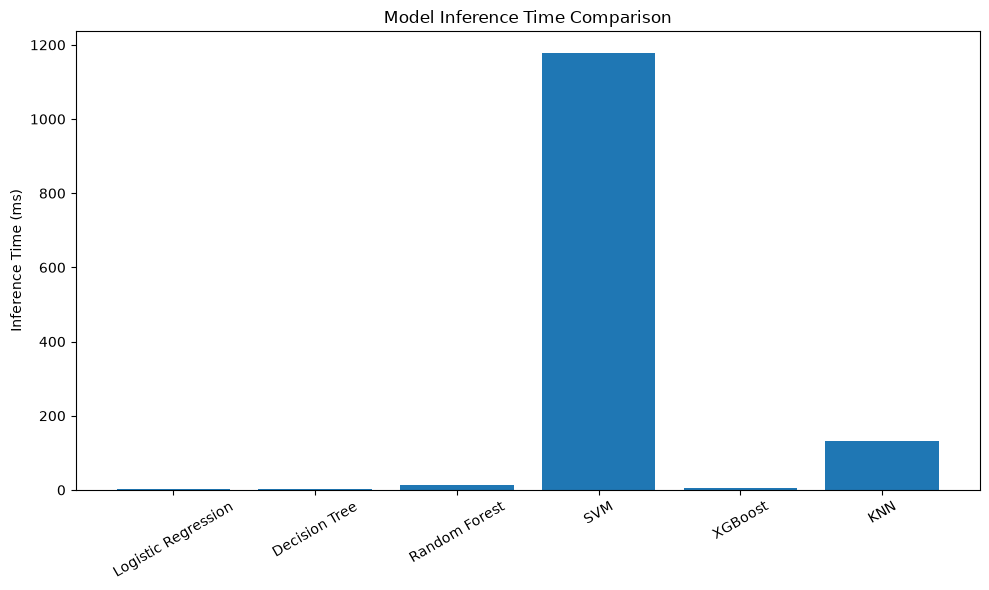

In [20]:
plt.figure(figsize=(10, 6))

plt.bar(
    results_df.index,
    results_df["inference_time"] * 1000
)

plt.ylabel("Inference Time (ms)")
plt.title("Model Inference Time Comparison")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [21]:
reverse_label_map = {v: k for k, v in label_to_int.items()}

y_pred_xgb_labels = pd.Series(y_pred_xgb).map(reverse_label_map)

model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm,
    "XGBoost": y_pred_xgb_labels,
    "KNN": y_pred_knn
}

class_names = activity_labels["activity"].tolist()

per_class_f1 = {}

for model_name, predictions in model_predictions.items():
    per_class_f1[model_name] = f1_score(
        y_test,
        predictions,
        labels=class_names,
        average=None
    )

per_class_f1_df = pd.DataFrame(
    per_class_f1,
    index=class_names
)

print(per_class_f1_df.round(4))

                    Logistic Regression  Decision Tree  Random Forest     SVM  \
WALKING                          0.9686         0.8727         0.9251  0.9625   
WALKING_UPSTAIRS                 0.9560         0.8048         0.8943  0.9445   
WALKING_DOWNSTAIRS               0.9771         0.8571         0.9132  0.9517   
SITTING                          0.9241         0.7970         0.8990  0.9144   
STANDING                         0.9377         0.8271         0.9089  0.9263   
LAYING                           1.0000         1.0000         1.0000  1.0000   

                    XGBoost     KNN  
WALKING              0.9442  0.9099  
WALKING_UPSTAIRS     0.9223  0.8943  
WALKING_DOWNSTAIRS   0.9376  0.8564  
SITTING              0.8811  0.8466  
STANDING             0.9010  0.8777  
LAYING               1.0000  0.9972  


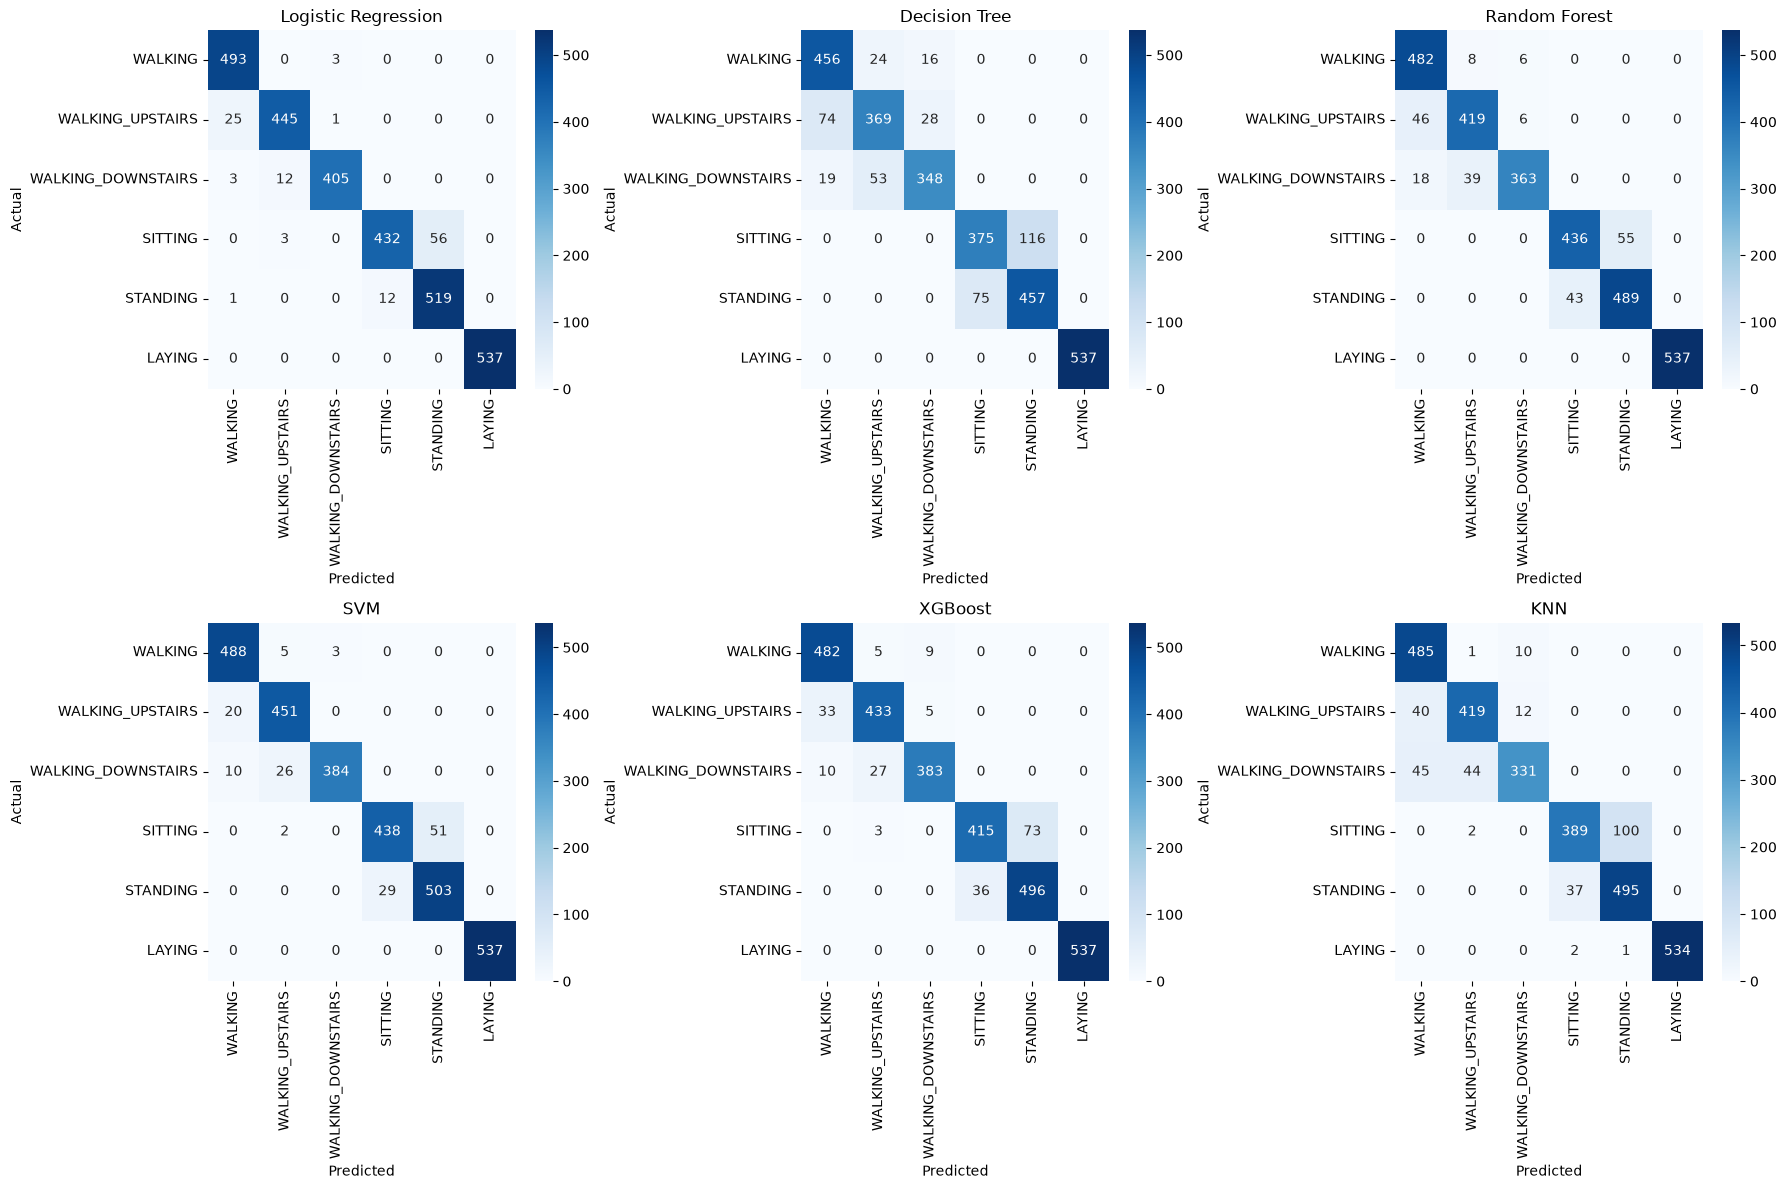

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (model_name, predictions) in zip(
    axes.flat,
    model_predictions.items()
):
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [23]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "XGBoost",
        "KNN"
    ],
    "Accuracy (%)": [
        accuracy_lr * 100,
        accuracy_dt * 100,
        accuracy_rf * 100,
        accuracy_svm * 100,
        accuracy_xgb * 100,
        accuracy_knn * 100
    ],
    "Macro F1 (%)": [
        f1_lr * 100,
        f1_dt * 100,
        f1_rf * 100,
        f1_svm * 100,
        f1_xgb * 100,
        f1_knn * 100
    ],
    "Inference Time (ms)": [
        inference_time * 1000,
        inference_time_dt * 1000,
        inference_time_rf * 1000,
        inference_time_svm * 1000,
        inference_time_xgb * 1000,
        inference_time_knn * 1000
    ]
})

print(final_results.round(3))

                 Model  Accuracy (%)  Macro F1 (%)  Inference Time (ms)
0  Logistic Regression        96.064        96.056                1.608
1        Decision Tree        86.257        85.981                1.709
2        Random Forest        92.501        92.343               12.935
3                  SVM        95.046        94.991             1177.624
4              XGBoost        93.180        93.102                5.409
5                  KNN        90.024        89.702              131.950


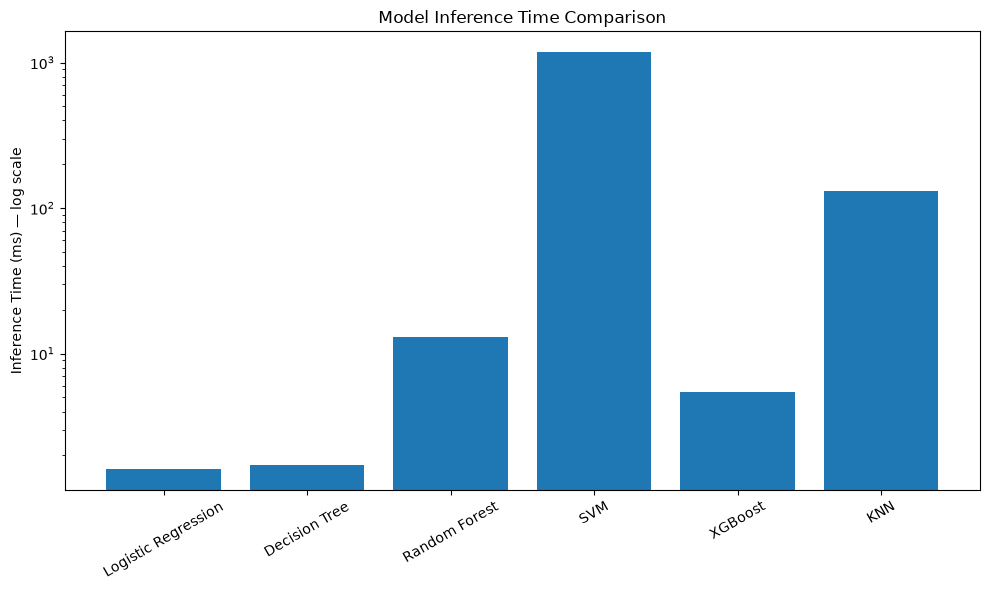

In [24]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_results["Model"],
    final_results["Inference Time (ms)"]
)

plt.yscale("log")

plt.ylabel("Inference Time (ms) — log scale")
plt.title("Model Inference Time Comparison")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Subject-aware cross-validation and hyperparameter optimization

The official UCI HAR test set remains untouched for final evaluation. Model selection is performed only on the training set using five-fold `GroupKFold`, where the subject identifier is the grouping variable. This prevents windows from the same participant appearing in both a training fold and its validation fold. Each search is optimized for macro F1, while both cross-validation accuracy and macro F1 are reported.

In [25]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
import numpy as np

# Subject IDs are used only for grouping; they are not model features.
subject_train = pd.read_csv(
    "train/subject_train.txt", sep=r"\s+", header=None
)[0].to_numpy()

group_cv = GroupKFold(n_splits=5)
cv_splits = list(group_cv.split(X_train, y_train, groups=subject_train))

# Verify that no subject is shared between training and validation in any fold.
for fold_number, (train_idx, validation_idx) in enumerate(cv_splits, start=1):
    train_subjects = set(subject_train[train_idx])
    validation_subjects = set(subject_train[validation_idx])
    assert train_subjects.isdisjoint(validation_subjects)
    print(
        f"Fold {fold_number}: "
        f"{len(train_subjects)} training subjects, "
        f"{len(validation_subjects)} validation subjects"
    )

# Majority-class baseline for context.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
print("\nMajority-class baseline on the official test set")
print(f"Accuracy: {accuracy_score(y_test, baseline_predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, baseline_predictions, average='macro'):.4f}")

Fold 1: 17 training subjects, 4 validation subjects
Fold 2: 17 training subjects, 4 validation subjects
Fold 3: 17 training subjects, 4 validation subjects
Fold 4: 17 training subjects, 4 validation subjects
Fold 5: 16 training subjects, 5 validation subjects

Majority-class baseline on the official test set
Accuracy: 0.1822
Macro F1: 0.0514


In [26]:
# Compact randomized searches keep the experiment reproducible and practical.
# Increase n_iter or expand the parameter lists for a more exhaustive study.
search_spaces = {
    "Logistic Regression": {
        "estimator": LogisticRegression(max_iter=3000),
        "parameters": {
            "C": [0.01, 0.1, 1.0, 10.0, 100.0],
            "solver": ["lbfgs", "liblinear"],
            "class_weight": [None, "balanced"]
        },
        "integer_labels": False
    },
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=42),
        "parameters": {
            "max_depth": [None, 5, 10, 20, 30],
            "min_samples_split": [2, 5, 10, 20],
            "min_samples_leaf": [1, 2, 5, 10],
            "class_weight": [None, "balanced"]
        },
        "integer_labels": False
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=42, n_jobs=-1),
        "parameters": {
            "n_estimators": [100, 200, 300],
            "max_depth": [None, 10, 20, 30],
            "min_samples_leaf": [1, 2, 5],
            "max_features": ["sqrt", "log2", 0.5]
        },
        "integer_labels": False
    },
    "SVM (RBF)": {
        "estimator": SVC(kernel="rbf"),
        "parameters": {
            "C": [0.1, 1.0, 10.0, 100.0],
            "gamma": ["scale", "auto", 0.001, 0.01, 0.1],
            "class_weight": [None, "balanced"]
        },
        "integer_labels": False
    },
    "XGBoost": {
        "estimator": XGBClassifier(
            random_state=42, n_jobs=-1, eval_metric="mlogloss"
        ),
        "parameters": {
            "n_estimators": [100, 200, 300],
            "max_depth": [3, 4, 6, 8],
            "learning_rate": [0.01, 0.05, 0.1, 0.2],
            "subsample": [0.7, 0.85, 1.0],
            "colsample_bytree": [0.7, 0.85, 1.0]
        },
        "integer_labels": True
    },
    "KNN": {
        "estimator": KNeighborsClassifier(),
        "parameters": {
            "n_neighbors": [3, 5, 7, 9, 11, 15],
            "weights": ["uniform", "distance"],
            "p": [1, 2]
        },
        "integer_labels": False
    }
}

scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro"}
search_results = []
optimized_models = {}

for model_name, specification in search_spaces.items():
    y_search = y_train_xgb if specification["integer_labels"] else y_train
    y_final = y_test_xgb if specification["integer_labels"] else y_test

    search = RandomizedSearchCV(
        estimator=specification["estimator"],
        param_distributions=specification["parameters"],
        n_iter=10,
        scoring=scoring,
        refit="f1_macro",
        cv=cv_splits,
        random_state=42,
        n_jobs=-1,
        return_train_score=False
    )

    print(f"\nOptimizing {model_name}...")
    search.fit(X_train, y_search)
    best_index = search.best_index_
    final_predictions = search.best_estimator_.predict(X_test)

    optimized_models[model_name] = search.best_estimator_
    search_results.append({
        "Model": model_name,
        "CV Accuracy Mean (%)": (
            search.cv_results_["mean_test_accuracy"][best_index] * 100
        ),
        "CV Accuracy Std (%)": (
            search.cv_results_["std_test_accuracy"][best_index] * 100
        ),
        "CV Macro F1 Mean (%)": (
            search.cv_results_["mean_test_f1_macro"][best_index] * 100
        ),
        "CV Macro F1 Std (%)": (
            search.cv_results_["std_test_f1_macro"][best_index] * 100
        ),
        "Final Test Accuracy (%)": accuracy_score(
            y_final, final_predictions
        ) * 100,
        "Final Test Macro F1 (%)": f1_score(
            y_final, final_predictions, average="macro"
        ) * 100,
        "Best Parameters": search.best_params_
    })
    print("Best parameters:", search.best_params_)

optimized_results_df = pd.DataFrame(search_results).set_index("Model")
display(optimized_results_df)

print("\nImportant: the official test metrics above are final evaluation results.")
print("Do not use them to select or retune hyperparameters.")


Optimizing Logistic Regression...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:489: FitFailedWarning: 
30 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/opt/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py", line 1488, in fit
    ra

Best parameters: {'solver': 'lbfgs', 'class_weight': None, 'C': 1.0}

Optimizing Decision Tree...


Best parameters: {'min_samples_split': 5, 'min_samples_leaf': 10, 'max_depth': 20, 'class_weight': 'balanced'}

Optimizing Random Forest...


Best parameters: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}

Optimizing SVM (RBF)...


Best parameters: {'gamma': 0.001, 'class_weight': 'balanced', 'C': 100.0}

Optimizing XGBoost...


Best parameters: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.7}

Optimizing KNN...


Best parameters: {'weights': 'distance', 'p': 1, 'n_neighbors': 15}


,CV Accuracy Mean (%),CV Accuracy Std (%),CV Macro F1 Mean (%),CV Macro F1 Std (%),Final Test Accuracy (%),Final Test Macro F1 (%),Best Parameters
Model,,,,,,,
Logistic Regression,93.856247,4.045627,93.715979,4.362640,96.063794,96.055692,"{'solver': 'lbfgs', 'class_weight': None, 'C':..."
Decision Tree,86.703388,2.494307,86.368901,2.618209,86.698337,86.398620,"{'min_samples_split': 5, 'min_samples_leaf': 1..."
Random Forest,93.046982,3.880249,92.868396,4.175449,94.095691,93.829503,"{'n_estimators': 300, 'min_samples_leaf': 1, '..."
SVM (RBF),93.708947,3.607128,93.589153,3.874211,96.267391,96.268495,"{'gamma': 0.001, 'class_weight': 'balanced', '..."
XGBoost,93.943117,3.443245,93.991576,3.434727,95.385137,95.356515,"{'subsample': 0.7, 'n_estimators': 200, 'max_d..."
KNN,90.414403,2.938259,90.189477,3.173048,91.788259,91.425907,"{'weights': 'distance', 'p': 1, 'n_neighbors':..."



Important: the official test metrics above are final evaluation results.
Do not use them to select or retune hyperparameters.
